In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "globals.json").exists())
os.chdir(REPO)

LDA_DIR, K = REPO / "Datastore/school_board_LDA_K20", 20   # final cleaned LDA export (seed 236)
BALANCED = True             # True: keep only districts with meetings in every year
BASE_YEARS = [2018, 2019]   # pre-COVID baseline
SEED = 236
T = [f"t{i}" for i in range(1, K + 1)]   # topic columns

## Load topic weights

In [2]:
meetings = pd.read_csv(LDA_DIR / "meeting_topic_weights.csv", dtype={"id": str, "leaid": str}, parse_dates=["date"])
print(f"dropping {meetings['title_year_conflict'].sum():,} title-year conflicts of {len(meetings):,} meetings")
meetings = (meetings.loc[~meetings["title_year_conflict"]]
            .rename(columns={f"topic_{i:02d}": f"t{i}" for i in range(1, K + 1)})
            .assign(leaid=lambda d: d["leaid"].str.zfill(7))
            .reset_index(drop=True))
assert np.allclose(meetings[T].sum(axis=1), 1), "topic weights should sum to 1 per meeting"

terms = pd.read_csv(LDA_DIR / f"topics_k{K}.csv")
labels = pd.Series([f"t{t}: {l}" for t, l in zip(terms["topic"], terms["label"])], index=T)

display(meetings.groupby("year").agg(meetings=("id", "size"), districts=("leaid", "nunique")).T)

dropping 38 title-year conflicts of 83,366 meetings


year,2018,2019,2020,2021,2022,2023
meetings,6051,7297,13978,17779,18747,19476
districts,432,524,1061,1190,1261,1251


## Overview of topics

,topic,label,top_terms,district_mean (%),top_topic_share (%)
t20,20,Informal discussion and disagreement,"yeah, think, no, kids, people, back, mean, need, time, there's",10.4,11.4
t5,5,Motions and voting,"motion, mr, board, item, agenda, discussion, approve, aye, favor, meeting",9.8,12.7
t4,4,General deliberation,"think, things, kind, there's, yeah, something, need, lot, make, question",7.7,10.7
t3,3,Scheduling and meeting logistics,"meeting, next, week, day, board, time, last, year, days, committee",6.7,3.1
t14,14,Staff appreciation and school updates,"students, work, great, community, staff, teachers, things, see, year, kids",6.5,6.6
t1,1,Meeting introductions and formal address,"board, mr, dr, evening, miss, district, members, students, high, county",6.4,7.9
t9,9,Budgets and finance,"budget, year, dollars, fund, money, state, funds, tax, funding, increase",6.4,10.1
t13,13,Curriculum and instruction,"students, grade, teachers, year, learning, math, student, level, high, curriculum",5.3,8.0
t10,10,Board policy and governance,"board, policy, think, committee, members, make, no, policies, public, member",4.8,4.7
t16,16,Sports and student activities,"high, year, team, students, state, sports, great, student, coach, girls",4.7,3.0


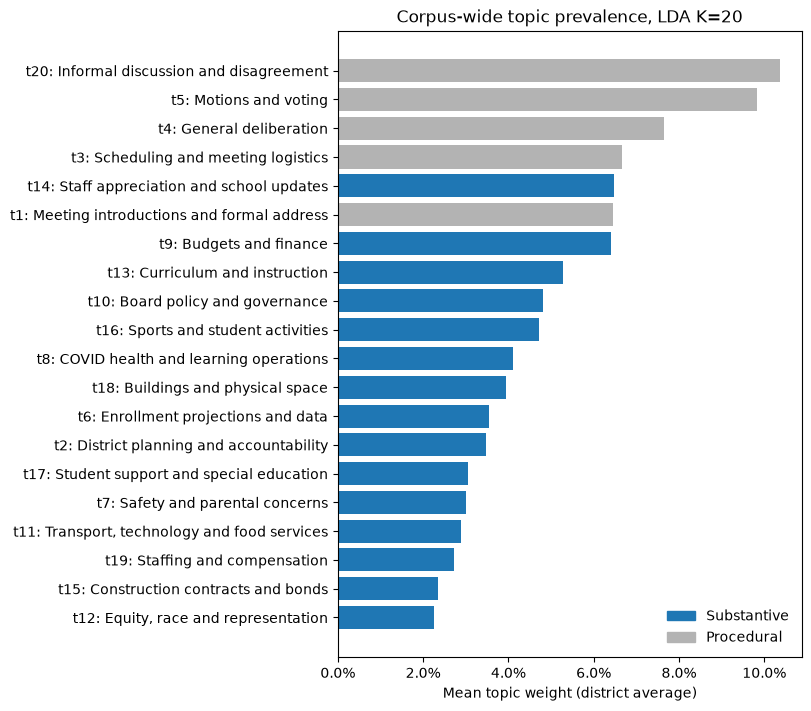

In [3]:
# corpus-wide topic prominence (all years, all districts)
PROCEDURAL = ["t1", "t3", "t4", "t5", "t20"]   # meeting boilerplate rather than substantive issues
prom = terms[["topic", "label", "top_terms"]].set_index(pd.Index(T)).assign(
    district_mean=meetings.groupby("leaid")[T].mean().mean(),   # avg topic weight, every district counts equally
    top_topic_share=meetings[T].idxmax(axis=1).value_counts(normalize=True).reindex(T, fill_value=0),  # share of meetings where it's the largest topic
).sort_values("district_mean", ascending=False)

with pd.option_context("display.max_colwidth", None):
    display(prom.assign(district_mean=(prom["district_mean"] * 100).round(1),
                        top_topic_share=(prom["top_topic_share"] * 100).round(1))
                .rename(columns={"district_mean": "district_mean (%)", "top_topic_share": "top_topic_share (%)"}))

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
p = prom[::-1]
ax.barh(labels[p.index], p["district_mean"], color=["0.7" if t in PROCEDURAL else "C0" for t in p.index])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="C0"), plt.Rectangle((0, 0), 1, 1, color="0.7")],
          labels=["Substantive", "Procedural"], loc="lower right", frameon=False)
ax.set(xlabel="Mean topic weight (district average)", title=f"Corpus-wide topic prevalence, LDA K={K}")
plt.show()

In [4]:
# step 1: district-year = mean over its meetings; step 2: year = mean over districts (one vote per district)
dy = meetings.groupby(["leaid", "year"])[T].mean().reset_index()
years = sorted(dy["year"].unique())
if BALANCED:
    keep = dy.groupby("leaid")["year"].nunique().loc[lambda s: s == len(years)].index
    dy = dy[dy["leaid"].isin(keep)].reset_index(drop=True)
print(f"{dy['leaid'].nunique():,} districts, {len(dy):,} district-years ({'balanced' if BALANCED else 'unbalanced'})")

trend = dy.groupby("year")[T].mean()
dev = trend - trend.loc[BASE_YEARS].mean()   # change from the 2018-19 baseline

363 districts, 2,178 district-years (balanced)


## Topic trends

In [7]:
N_BOOT = 500                # district bootstrap draws for the CIs
N_HIGHLIGHT = 4             # colour the topics that move most from the baseline
HIGHLIGHT = None            # or pick by hand, e.g. ["t8", "t12", "t7", "t9"]
SKIP_PROCEDURAL = False      # don't auto-highlight boilerplate topics

# resample whole districts so CIs reflect between-district variation
rng = np.random.default_rng(SEED)
leaids = dy["leaid"].unique()
by_d = {l: g for l, g in dy.groupby("leaid")}
boot = np.stack([
    pd.concat([by_d[l] for l in rng.choice(leaids, len(leaids))]).groupby("year")[T].mean().reindex(years).to_numpy()
    for _ in range(N_BOOT)
])
lo, hi = (pd.DataFrame(np.nanpercentile(boot, q, axis=0), index=years, columns=T) for q in (2.5, 97.5))

# rank topics by their largest change from the 2018-19 baseline (dev from the panel cell)
bdev = boot - np.nanmean(boot[:, [years.index(y) for y in BASE_YEARS]], axis=1, keepdims=True)
peak_year = dev.abs().idxmax()
rank = pd.DataFrame({
    "label": labels,
    "base": trend.loc[BASE_YEARS].mean(),
    "peak_year": peak_year,
    "peak_change": [dev.loc[peak_year[t], t] for t in T],
    "ci_lo": [np.nanpercentile(bdev[:, years.index(peak_year[t]), i], 2.5) for i, t in enumerate(T)],
    "ci_hi": [np.nanpercentile(bdev[:, years.index(peak_year[t]), i], 97.5) for i, t in enumerate(T)],
})
rank["rel_change"] = rank["peak_change"] / rank["base"]
rank = rank.reindex(rank["peak_change"].abs().sort_values(ascending=False).index)
display(rank.round(3))

,label,base,peak_year,peak_change,ci_lo,ci_hi,rel_change
t8,t8: COVID health and learning operations,0.007,2020,0.092,0.087,0.096,13.350
t16,t16: Sports and student activities,0.053,2020,-0.025,-0.027,-0.022,-0.462
t1,t1: Meeting introductions and formal address,0.081,2020,-0.019,-0.024,-0.015,-0.237
t5,t5: Motions and voting,0.087,2023,0.017,0.011,0.023,0.194
t7,t7: Safety and parental concerns,0.029,2021,0.016,0.013,0.019,0.543
t18,t18: Buildings and physical space,0.044,2021,-0.014,-0.017,-0.011,-0.316
t13,t13: Curriculum and instruction,0.061,2020,-0.014,-0.016,-0.012,-0.226
t20,t20: Informal discussion and disagreement,0.090,2023,-0.014,-0.017,-0.010,-0.150
t4,t4: General deliberation,0.073,2020,0.013,0.010,0.015,0.178
t15,t15: Construction contracts and bonds,0.032,2020,-0.010,-0.012,-0.009,-0.323


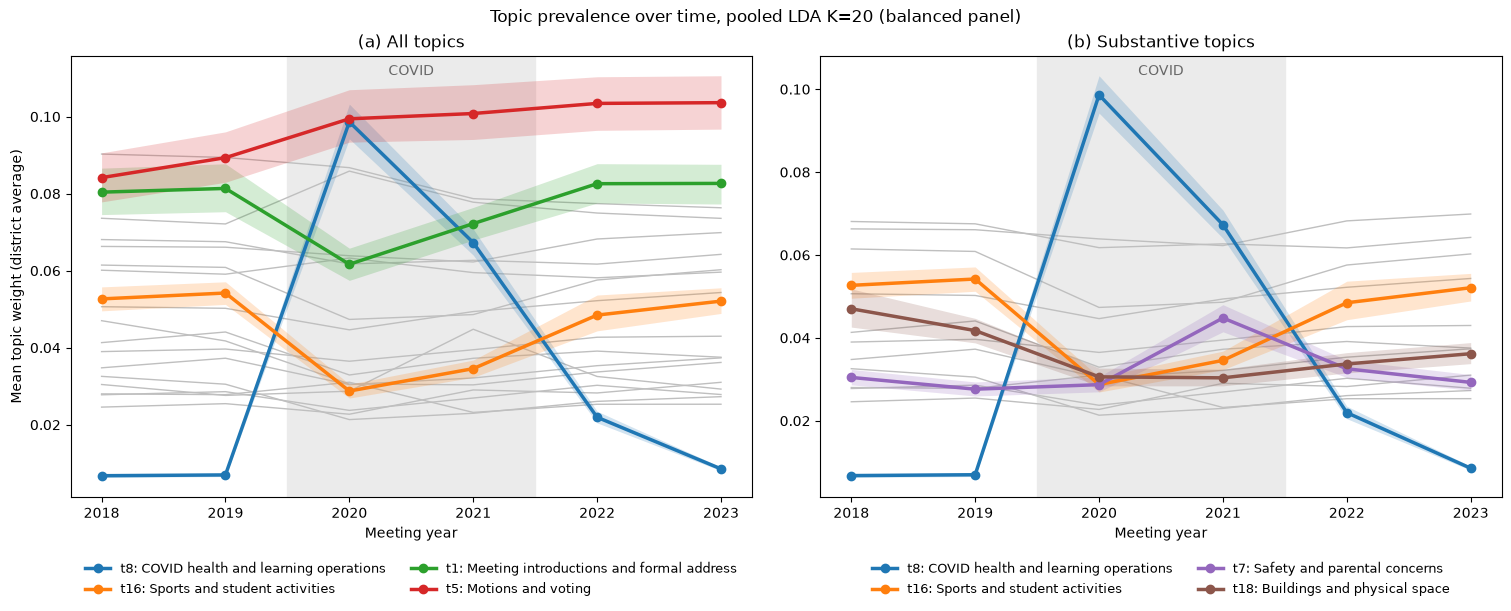

In [9]:
SUBST = [t for t in T if t not in PROCEDURAL]
hl_all = rank.index[:N_HIGHLIGHT].tolist()                          # biggest movers, all topics
hl_sub = [t for t in rank.index if t in SUBST][:N_HIGHLIGHT]        # biggest movers, substantive only
color = {t: f"C{i}" for i, t in enumerate(dict.fromkeys(hl_all + hl_sub))}   # one colour per topic, shared across panels

fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
for ax, topics, hl, title in [(axes[0], T, hl_all, "(a) All topics"),
                              (axes[1], SUBST, hl_sub, "(b) Substantive topics")]:
    for t in topics:
        if t not in hl:
            ax.plot(years, trend[t], color="0.75", lw=1, zorder=1)
    for t in hl:
        ax.fill_between(years, lo[t], hi[t], color=color[t], alpha=.2, lw=0, zorder=2)
        ax.plot(years, trend[t], color=color[t], lw=2.5, marker="o", zorder=3, label=labels[t])
    ax.axvspan(2019.5, 2021.5, color="0.92", zorder=0)
    ax.text(2020.5, 0.98, "COVID", transform=ax.get_xaxis_transform(), ha="center", va="top", color="0.4")
    ax.set(xlabel="Meeting year", xticks=years, title=title)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2, frameon=False, fontsize=9)
axes[0].set_ylabel("Mean topic weight (district average)")
fig.suptitle(f"Topic prevalence over time, pooled LDA K={K} ({'balanced panel' if BALANCED else 'all districts'})")
plt.show()

## Clustering

In [11]:
import importlib, sys
sys.path.insert(0, str(REPO / "source/analysis/lda_cleaned"))
import lda_cluster as lc
importlib.reload(lc)

GOP = "gop_2p_2020"   # county two-party GOP share (fixed per district)
assert BALANCED, "clustering assumes the balanced panel from the panel cell"
panel = lc.AddCovariates(dy).dropna(subset=[GOP, "locale"]).reset_index(drop=True)
print(f"balanced panel: {panel['leaid'].nunique()} districts x {len(years)} years = {len(panel):,} rows")

# z = (weight - that year's mean) / that year's SD: a district's emphasis relative to other districts in the same year,
# so common shocks (e.g. the 2020 COVID spike) drop out and the directions mean the same thing every year
Tz = [t for t in T if panel[t].mean() >= .02]   # standardizing tiny topics mostly amplifies noise
Z = panel[Tz].groupby(panel["year"]).transform(lambda c: (c - c.mean()) / c.std(ddof=0))
zp = pd.concat([panel[["leaid", "year"]], Z], axis=1)
sp = lc.Decompose(zp, Tz, standardize=True, min_topic_mean=-np.inf)   # SVD; columns already mean 0 / SD 1
print(f"topics used: {len(Tz)} of {K}")

merge: 100.0% matched; gop_2p_2020 99.7%, locale 100.0%
balanced panel: 362 districts x 6 years = 2,172 rows
topics used: 20 of 20


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
singular_value,85.30,72.79,62.71,61.90,54.51,50.71,48.72,45.07,42.62,41.24,37.92,37.30,34.84,33.20,32.43,31.41,29.93,27.84,26.76,8.01
var_explained (%),16.75,12.20,9.05,8.82,6.84,5.92,5.46,4.68,4.18,3.92,3.31,3.20,2.79,2.54,2.42,2.27,2.06,1.78,1.65,0.15
cumulative (%),16.75,28.95,38.00,46.82,53.66,59.58,65.05,69.72,73.90,77.82,81.13,84.33,87.13,89.66,92.09,94.36,96.42,98.20,99.85,100.00


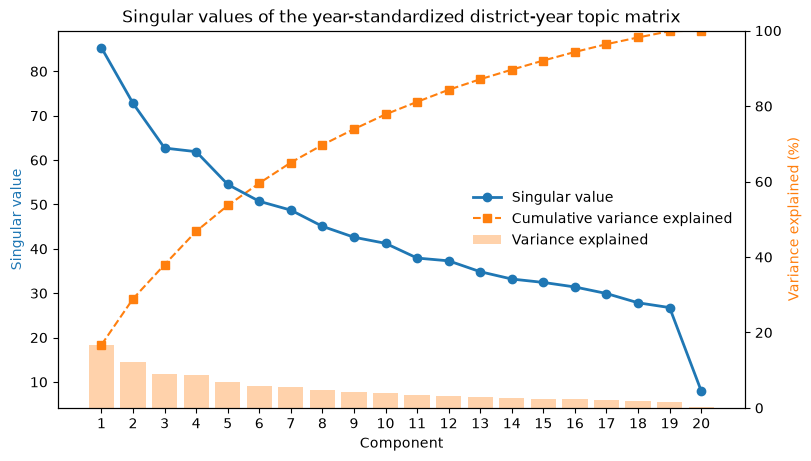

In [12]:
s = sp["s"]
var_exp = s**2 / (s**2).sum()   # share of total variance captured by each direction
idx = np.arange(1, len(s) + 1)
display(pd.DataFrame({"singular_value": s, "var_explained (%)": 100 * var_exp,
                      "cumulative (%)": 100 * var_exp.cumsum()}, index=idx).round(2).T)

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.plot(idx, s, "o-", color="C0", lw=2, label="Singular value")
ax.set(xlabel="Component", ylabel="Singular value", xticks=idx)
ax.yaxis.label.set_color("C0")
ax2 = ax.twinx()
ax2.bar(idx, 100 * var_exp, color="C1", alpha=.35, label="Variance explained")
ax2.plot(idx, 100 * var_exp.cumsum(), "s--", color="C1", lw=1.5, label="Cumulative variance explained")
ax2.set(ylabel="Variance explained (%)", ylim=(0, 100))
ax2.yaxis.label.set_color("C1")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)   # keep the singular-value line on top of the bars
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", frameon=False)
ax.set_title("Singular values of the year-standardized district-year topic matrix")
plt.show()

## Clustering results

In [13]:
NCLUST = 3   # rank r = 2 -> r + 1 = 3 clusters
cl, emb = lc.Cluster(sp, NCLUST)   # k-means on U[:, :2], the top two left singular vectors

# k-means numbering is arbitrary: renumber so C0 has the lowest mean GOP share and C2 the highest
order = pd.Series(panel[GOP].to_numpy()).groupby(cl).mean().sort_values().index
cl = pd.Series(cl).map({old: new for new, old in enumerate(order)}).to_numpy()
panel["cluster"] = cl
zp["cluster"] = cl

# name each cluster by the topics it over-/under-emphasizes (mean within-year z-score)
prof = zp.groupby("cluster")[Tz].mean()
cname = pd.Series({c: f"C{c}: " + ", ".join([f"{t.upper()}+" for t in r.nlargest(2).index] +
                                              [f"{t.upper()}\u2212" for t in r.nsmallest(1).index])
                   for c, r in prof.iterrows()})
display(pd.DataFrame({"name": cname, "district-years": panel["cluster"].value_counts().sort_index(),
                      "mean GOP": panel.groupby("cluster")[GOP].mean().round(3)}))

,name,district-years,mean GOP
0,"C0: T2+, T4+, T16−",769,0.398
1,"C1: T1+, T5+, T4−",633,0.476
2,"C2: T18+, T20+, T1−",770,0.526


In [20]:
NCLUST = 3   # rank r = 2 -> r + 1 = 3 clusters
N_LABEL = 10 # label the longest topic arrows only
SHORT = {"t1": "Introductions", "t2": "Planning", "t3": "Scheduling", "t4": "Deliberation", "t5": "Motions",
         "t6": "Enrollment", "t7": "Safety & parents", "t8": "COVID", "t9": "Budget", "t10": "Board policy",
         "t11": "Transport", "t12": "Equity", "t13": "Curriculum", "t14": "School updates", "t15": "Construction",
         "t16": "Athletics", "t17": "Student services", "t18": "Buildings", "t19": "Staffing", "t20": "Informal"}

cl, emb = lc.Cluster(sp, NCLUST)   # k-means on U[:, :2], the top two left singular vectors

# k-means numbering is arbitrary: renumber so C0 has the lowest mean GOP share and C2 the highest
order = pd.Series(panel[GOP].to_numpy()).groupby(cl).mean().sort_values().index
cl = pd.Series(cl).map({old: new for new, old in enumerate(order)}).to_numpy()
panel["cluster"] = cl
zp["cluster"] = cl

# name each cluster by the topics it over-/under-emphasizes (mean within-year z-score)
prof = zp.groupby("cluster")[Tz].mean()
cname = pd.Series({c: f"C{c}: " + ", ".join([f"{SHORT[t]}+" for t in r.nlargest(2).index] +
                                              [f"{SHORT[t]}\u2212" for t in r.nsmallest(1).index])
                   for c, r in prof.iterrows()})
display(pd.DataFrame({"name": cname, "district-years": panel["cluster"].value_counts().sort_index(),
                      "mean GOP": panel.groupby("cluster")[GOP].mean().round(3)}))

,name,district-years,mean GOP
0,"C0: Planning+, Deliberation+, Athletics−",769,0.398
1,"C1: Introductions+, Motions+, Deliberation−",633,0.476
2,"C2: Buildings+, Informal+, Introductions−",770,0.526


In [22]:
# covariance biplot: rows in standard coordinates (U), topics as corr(topic, component score) = s_k v_jk / sqrt(n)
n = sp["X"].shape[0]
load = pd.DataFrame(sp["Vt"][:2].T * sp["s"][:2] / np.sqrt(n), index=sp["topics"], columns=["v1", "v2"])
length = np.hypot(load["v1"], load["v2"])   # sqrt(share of the topic's variance captured by directions 1-2)
display(load.assign(label=[SHORT[t] for t in load.index], length=length).sort_values("length", ascending=False).round(3))
scale = .9 * np.abs(emb[:, :2]).max()        # one display constant for both axes: unit-length arrow reaches the cloud's edge

,v1,v2,label,length
t4,-0.440,-0.651,Deliberation,0.786
t1,-0.017,0.768,Introductions,0.768
t2,-0.689,-0.109,Planning,0.698
t5,0.439,0.514,Motions,0.676
t12,-0.660,0.114,Equity,0.670
t18,0.449,-0.431,Buildings,0.622
t6,-0.267,-0.531,Enrollment,0.595
t17,-0.546,0.179,Student services,0.575
t16,0.485,0.277,Athletics,0.559
t20,0.443,-0.302,Informal,0.536


[Text(0.5, 0, 'Cluster'),
 Text(0, 0.5, 'County GOP two-party share, 2020'),
 Text(0.5, 1.0, '(b) Partisanship by cluster, 2018–2023')]

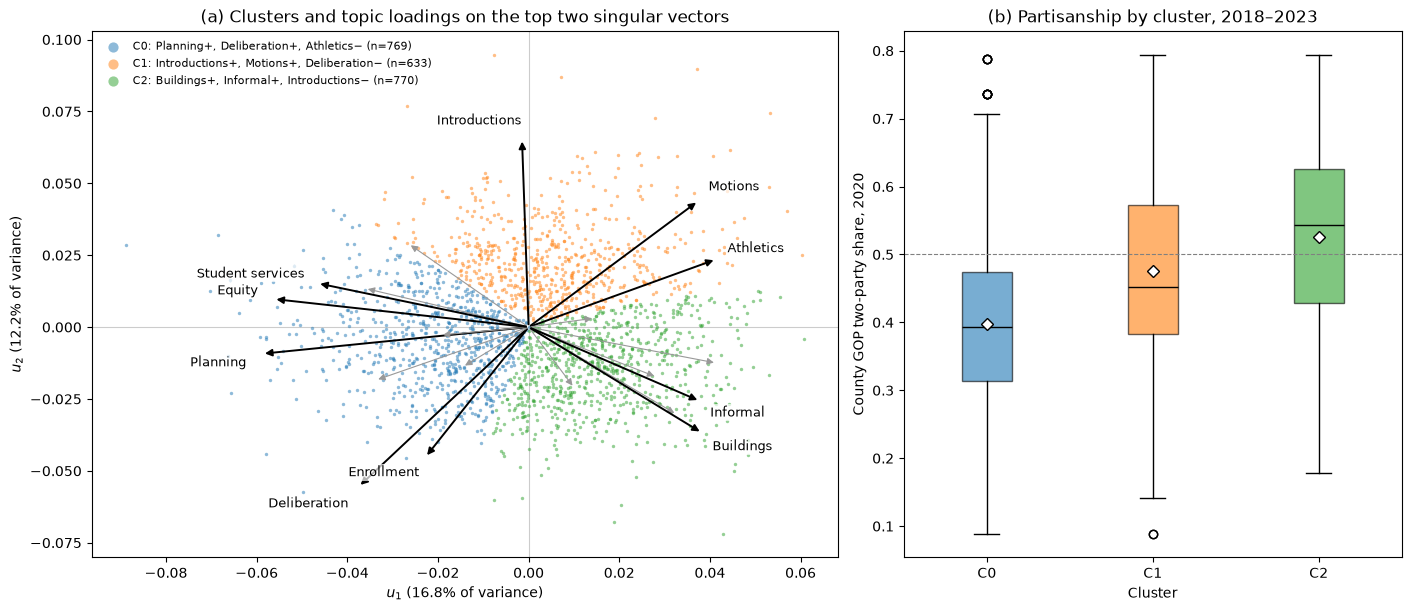

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]})

# (a) covariance biplot
ax = axes[0]
for c in range(NCLUST):
    m = cl == c
    ax.scatter(emb[m, 0], emb[m, 1], s=6, alpha=.5, color=f"C{c}", lw=0, label=f"{cname[c]} (n={m.sum()})")
for t, (x, y) in load.iterrows():
    on = t in length.nlargest(N_LABEL).index
    ax.annotate("", xy=(scale * x, scale * y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="k" if on else "0.6", lw=1.4 if on else .8))
    if on:
        ax.text(1.06 * scale * x, 1.06 * scale * y, SHORT[t], fontsize=9, ha="left" if x >= 0 else "right",
                va="bottom" if y >= 0 else "top", bbox=dict(fc="white", ec="none", alpha=.7, pad=1))

ax.axhline(0, color="0.8", lw=.8, zorder=0); ax.axvline(0, color="0.8", lw=.8, zorder=0)
ax.set(xlabel=f"$u_1$ ({100 * var_exp[0]:.1f}% of variance)", ylabel=f"$u_2$ ({100 * var_exp[1]:.1f}% of variance)",
       title="(a) Clusters and topic loadings on the top two singular vectors")
ax.legend(loc="upper left", fontsize=8, frameon=False, markerscale=3)

# (b) county GOP share by cluster, pooled over 2018-2023
ax = axes[1]
bp = ax.boxplot([panel.loc[panel["cluster"] == c, GOP] for c in range(NCLUST)],
                tick_labels=[f"C{c}" for c in range(NCLUST)], patch_artist=True, showmeans=True,
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=6),
                medianprops=dict(color="k"))
for c, box in enumerate(bp["boxes"]):
    box.set(facecolor=f"C{c}", alpha=.6)
ax.axhline(.5, color="gray", lw=.8, ls="--")
ax.set(xlabel="Cluster", ylabel="County GOP two-party share, 2020", title="(b) Partisanship by cluster, 2018\u20132023")

In [32]:
# correlation of each district-year's score on singular direction j (column j of U) with county GOP share
R = 2                                            # top two directions
U = sp["U"][:, :R]                               # rows line up with panel (zp was built from panel)
g = panel[GOP].to_numpy()
r_obs = np.array([np.corrcoef(U[:, j], g)[0, 1] for j in range(R)])

# each district appears once per year, so resample whole districts for the CI (directions held fixed, not refit)
rng = np.random.default_rng(SEED)
row_ix = panel.groupby("leaid").indices
ids = list(row_ix)
boot_r = np.array([[np.corrcoef(U[ix, j], g[ix])[0, 1] for j in range(R)]
                   for ix in (np.concatenate([row_ix[l] for l in rng.choice(ids, len(ids))]) for _ in range(N_BOOT))])

# SVD signs are arbitrary: "high end" = topics loading positively, so r > 0 means the high end leans GOP
V = pd.DataFrame(sp["Vt"][:R].T, index=[SHORT[t] for t in sp["topics"]], columns=[f"u{j + 1}" for j in range(R)])
display(pd.DataFrame({
    "r_gop": r_obs,
    "ci_lo": np.percentile(boot_r, 2.5, axis=0),
    "ci_hi": np.percentile(boot_r, 97.5, axis=0),
    "low_end": [", ".join(V[c].nsmallest(3).index) for c in V],
    "high_end": [", ".join(V[c].nlargest(3).index) for c in V],
}, index=V.columns).round(3))

# same correlation within each year (is the partisan axis stable over time?)
display(pd.DataFrame({y: [np.corrcoef(U[m, j], g[m])[0, 1] for j in range(R)]
                      for y in years for m in [(panel["year"] == y).to_numpy()]}, index=V.columns).round(3))

,r_gop,ci_lo,ci_hi,low_end,high_end
u1,0.466,0.392,0.532,"Planning, Equity, Student services","Transport, Athletics, Buildings"
u2,-0.023,-0.106,0.070,"Deliberation, Enrollment, Buildings","Introductions, Motions, Safety & parents"


,2018,2019,2020,2021,2022,2023
u1,0.476,0.445,0.485,0.464,0.488,0.441
u2,-0.014,-0.052,-0.091,0.018,0.008,-0.007


## GOP share over time

In [26]:
gop_cy = panel.pivot_table(index="year", columns="cluster", values=GOP, aggfunc="mean")
overall = panel.drop_duplicates("leaid")[GOP].mean()
print(f"mean {GOP} by cluster and year (overall district mean {overall:.3f}):")
display(gop_cy.rename(columns=cname).round(3))

mean gop_2p_2020 by cluster and year (overall district mean 0.466):


cluster,"C0: Planning+, Deliberation+, Athletics−","C1: Introductions+, Motions+, Deliberation−","C2: Buildings+, Informal+, Introductions−"
year,,,
2018,0.398,0.477,0.521
2019,0.403,0.471,0.523
2020,0.398,0.450,0.539
2021,0.395,0.476,0.528
2022,0.396,0.487,0.526
2023,0.400,0.491,0.514


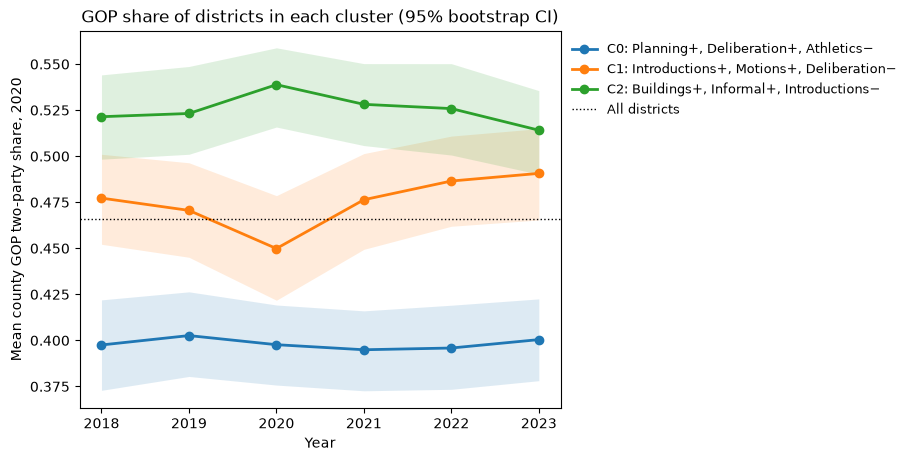

In [27]:
# resample whole districts (all six years together) so CIs reflect between-district variation
rng = np.random.default_rng(SEED)
ids = panel["leaid"].unique()
rows = {l: g for l, g in panel.groupby("leaid")}
gop_boot = np.stack([
    pd.concat([rows[l] for l in rng.choice(ids, len(ids))])
      .pivot_table(index="year", columns="cluster", values=GOP, aggfunc="mean").reindex(index=years, columns=range(NCLUST)).to_numpy()
    for _ in range(N_BOOT)])
glo, ghi = np.nanpercentile(gop_boot, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
for c in range(NCLUST):
    ax.fill_between(years, glo[:, c], ghi[:, c], color=f"C{c}", alpha=.15, lw=0)
    ax.plot(years, gop_cy[c], "o-", color=f"C{c}", lw=2, label=cname[c])
ax.axhline(overall, color="k", ls=":", lw=1, label="All districts")
ax.set(xlabel="Year", ylabel="Mean county GOP two-party share, 2020", xticks=years,
       title="GOP share of districts in each cluster (95% bootstrap CI)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False, fontsize=9)
plt.show()

## Locale

In [28]:
LOCALES = ["City", "Suburb", "Town", "Rural"]
loc_mix = pd.crosstab(panel["cluster"], panel["locale"], normalize="index").reindex(columns=LOCALES) * 100
loc_mix.loc["All"] = panel["locale"].value_counts(normalize=True).reindex(LOCALES) * 100   # baseline for comparison
loc_mix["n (district-years)"] = panel["cluster"].value_counts().reindex(loc_mix.index).fillna(len(panel)).astype(int)
loc_mix.index = [cname[c] if c in cname.index else c for c in loc_mix.index]
display(loc_mix.round(1))

locale,City,Suburb,Town,Rural,n (district-years)
"C0: Planning+, Deliberation+, Athletics−",41.5,47.6,5.1,5.9,769
"C1: Introductions+, Motions+, Deliberation−",21.2,61.3,9.0,8.5,633
"C2: Buildings+, Informal+, Introductions−",10.5,45.5,18.7,25.3,770
All,24.6,50.8,11.0,13.5,2172


In [29]:
# map: district clusters in 2021 over county GOP two-party share, 2020 (lower 48)
import json, urllib.request
from matplotlib.collections import PolyCollection

MAP_YEAR = 2021
GEO = REPO / "Datastore/District Covariates/elections/counties_geojson.json"   # cached county outlines (plotly, 2010 FIPS)
if not GEO.exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json", GEO)
votes = pd.read_parquet(REPO / "Datastore/District Covariates/processed/county_presidential.parquet").set_index("county_fips")[GOP]
polys, vals = [], []
for f in json.loads(GEO.read_text())["features"]:
    if f["id"][:2] in ("02", "15", "72"):   # lower 48 only
        continue
    g = f["geometry"]
    for poly in (g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]):
        polys.append(np.asarray(poly[0]))   # outer ring
        vals.append(votes.get(f["id"], np.nan))
vals = np.ma.masked_invalid(np.array(vals, dtype=float))
print(f"counties drawn with a {GOP} value: {(~vals.mask).mean():.1%}")

counties drawn with a gop_2p_2020 value: 99.9%


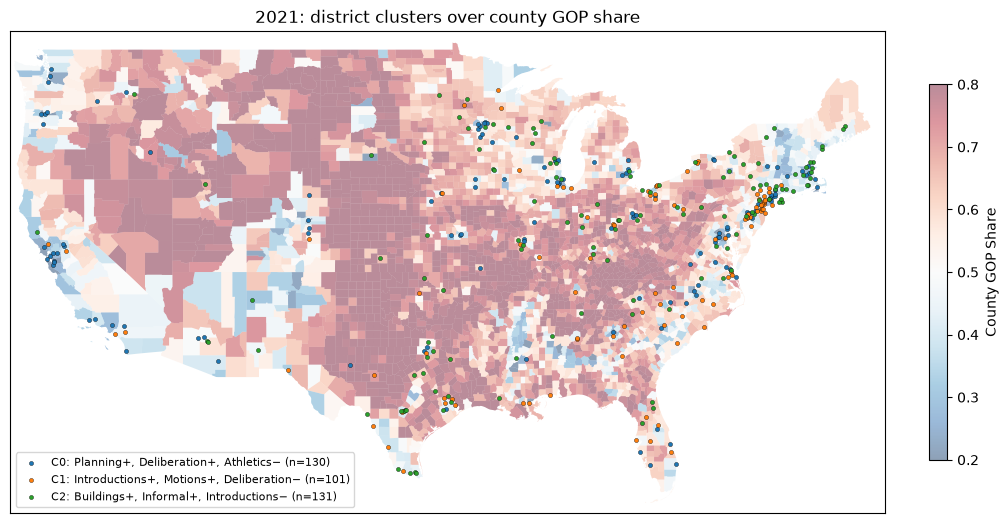

In [30]:
def MapYear(ax, p, title):
    pc = PolyCollection(polys, array=vals, cmap="RdBu_r", clim=(.2, .8), alpha=.45, linewidths=0)
    pc.cmap.set_bad("0.9")
    ax.add_collection(pc)
    m = p[p["longitude"].between(-125, -66) & p["latitude"].between(24, 50)]
    for c, g in m.groupby("cluster"):
        ax.scatter(g["longitude"], g["latitude"], s=9, color=f"C{c}", edgecolor="k", lw=.25, label=f"{cname[c]} (n={len(g)})")
    ax.set(xlim=(-125, -66), ylim=(24, 50), xticks=[], yticks=[], title=title)
    ax.set_aspect(1.25)
    return pc

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
pc = MapYear(ax, panel[panel["year"] == MAP_YEAR], f"{MAP_YEAR}: district clusters over county GOP share")
fig.colorbar(pc, ax=ax, shrink=.7, label="County GOP Share")
ax.legend(fontsize=8, loc="lower left")
plt.show()

### Check whether clusters just recover locale

In [31]:
# eta2   : share of variance in county GOP share explained by cluster membership
# perm p : eta2 vs. shuffling cluster labels only within locale (City/Suburb/Town/Rural), so a significant result
#          means clusters track partisanship beyond what urbanicity alone would produce
N_PERM = 2000
perm = []
for y in years:
    p = panel[panel["year"] == y]
    eta2, pval = lc.WithinStrataPerm(p[GOP], p["cluster"], p["locale"], n_perm=N_PERM)
    perm.append(dict(year=y, districts=len(p), eta2=eta2, eta2_locale_only=lc.Eta2(p[GOP], p["locale"]), perm_p=pval))
perm = pd.DataFrame(perm).set_index("year")

# pooled across years: shuffle within locale x year so each year keeps its own cluster sizes
eta2, pval = lc.WithinStrataPerm(panel[GOP], panel["cluster"], panel["locale"] + "_" + panel["year"].astype(str), n_perm=N_PERM)
perm.loc["All years"] = dict(districts=len(panel), eta2=eta2, eta2_locale_only=lc.Eta2(panel[GOP], panel["locale"]), perm_p=pval)
perm["districts"] = perm["districts"].astype(int)
display(perm.round(4))
print(f"p-values are based on {N_PERM:,} permutations; the smallest reportable value is {1 / N_PERM:.4f} (shown as 0)")

,districts,eta2,eta2_locale_only,perm_p
year,,,,
2018,362,0.1259,0.1378,0.0
2019,362,0.1207,0.1378,0.0
2020,362,0.1760,0.1378,0.0
2021,362,0.1529,0.1378,0.0
2022,362,0.1488,0.1378,0.0
2023,362,0.1200,0.1378,0.0
All years,2172,0.1374,0.1378,0.0


p-values are based on 2,000 permutations; the smallest reportable value is 0.0005 (shown as 0)
